In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [12]:
df = pd.read_csv(r'C:\Users\yajnasree\Downloads\lending_club_loan_two.csv')

In [14]:
meta_data = pd.read_csv(r'C:\Users\yajnasree\Downloads\lending_club_info.csv')

In [15]:
meta_data

,LoanStatNew,Description
0,loan_amnt,The listed amount of the loan applied for by t...
1,term,The number of payments on the loan. Values are...
2,int_rate,Interest Rate on the loan
3,installment,The monthly payment owed by the borrower if th...
4,grade,LC assigned loan grade
5,sub_grade,LC assigned loan subgrade
6,emp_title,The job title supplied by the Borrower when ap...
7,emp_length,Employment length in years. Possible values ar...
8,home_ownership,The home ownership status provided by the borr...
9,annual_inc,The self-reported annual income provided by th...


In [16]:
df.shape

(396030, 27)

In [17]:
df.head().T

,0,1,2,3,4
loan_amnt,10000.0,8000.0,15600.0,7200.0,24375.0
term,36 months,36 months,36 months,36 months,60 months
int_rate,11.44,11.99,10.49,6.49,17.27
installment,329.48,265.68,506.97,220.65,609.33
grade,B,B,B,A,C
sub_grade,B4,B5,B3,A2,C5
emp_title,Marketing,Credit analyst,Statistician,Client Advocate,Destiny Management Inc.
emp_length,10+ years,4 years,< 1 year,6 years,9 years
home_ownership,RENT,MORTGAGE,RENT,RENT,MORTGAGE
annual_inc,117000.0,65000.0,43057.0,54000.0,55000.0


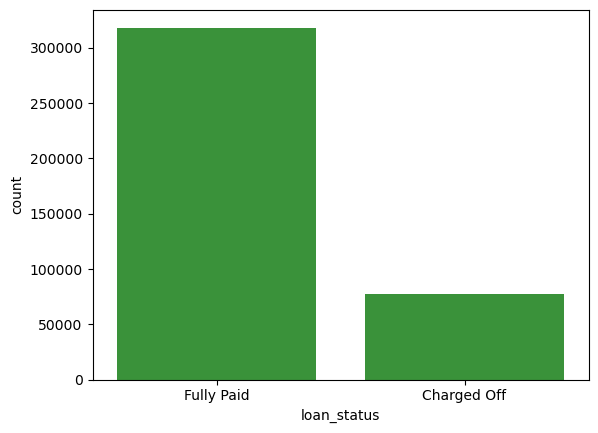

In [20]:
sns.countplot(x="loan_status",data=df)
plt.show()

In [22]:
df["loan_status"].value_counts()*100/len(df)

loan_status
Fully Paid     80.387092
Charged Off    19.612908
Name: count, dtype: float64

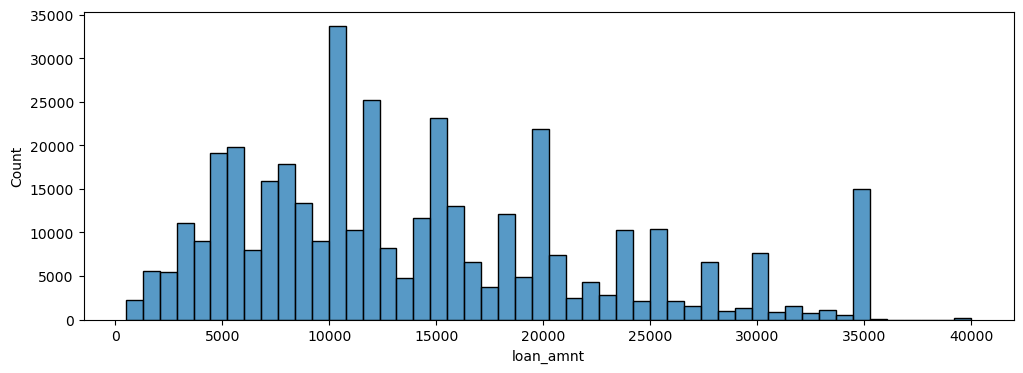

In [27]:
plt.figure(figsize=(12,4))
sns.histplot(df["loan_amnt"],bins=50)
plt.show()

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

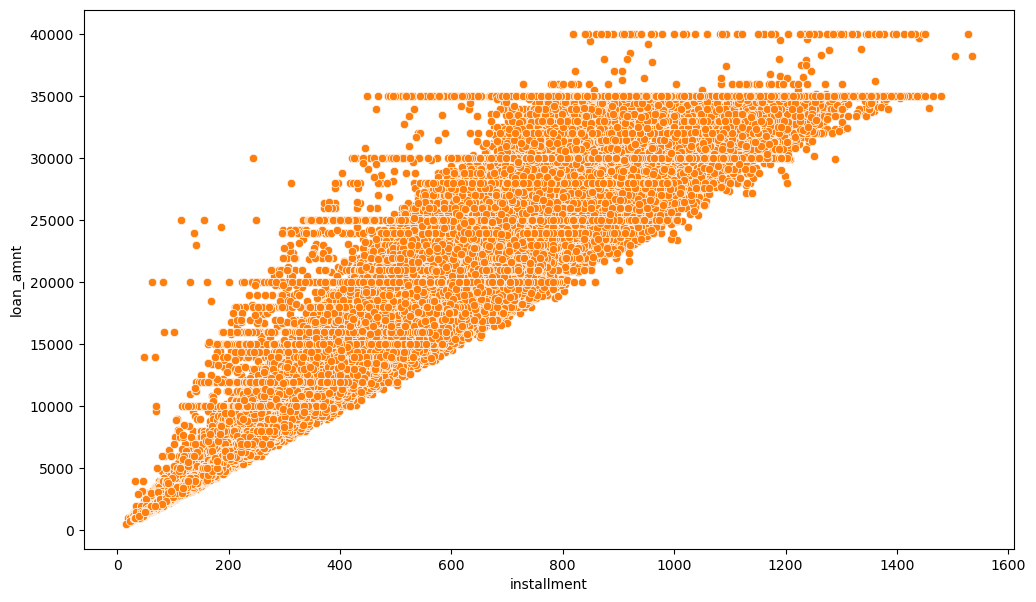

In [37]:
sns.scatterplot(x="installment",y="loan_amnt",data=df)
plt.show()

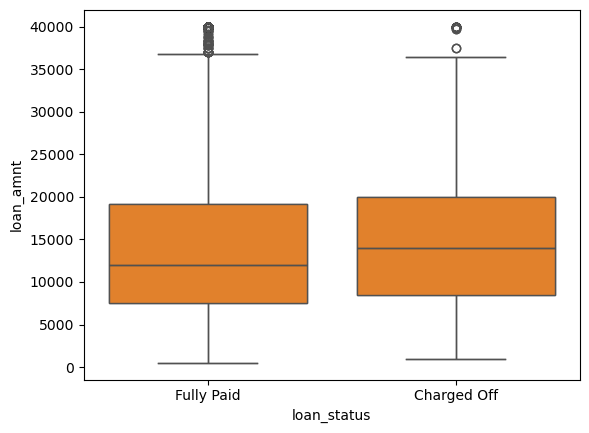

In [39]:
sns.boxplot(x="loan_status",y="loan_amnt",data=df)
plt.show()

In [40]:
df.groupby("loan_status")["loan_amnt"].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Charged Off,77673.0,15126.300967,8505.090557,1000.0,8525.0,14000.0,20000.0,40000.0
Fully Paid,318357.0,13866.878771,8302.319699,500.0,7500.0,12000.0,19225.0,40000.0


In [43]:
df["grade"].unique()

array(['B', 'A', 'C', 'E', 'D', 'F', 'G'], dtype=object)

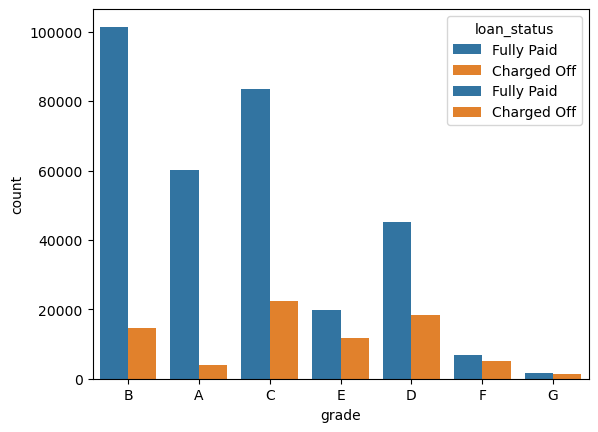

In [45]:
sns.countplot(x="grade",hue="loan_status",data=df)
plt.show()

In [51]:
df[df["grade"]=='A'].groupby("loan_status")["grade"].count()*100/len(df[df["grade"]=='A'])

loan_status
Charged Off     6.287878
Fully Paid     93.712122
Name: grade, dtype: float64

In [52]:
df[df["grade"]=='B'].groupby("loan_status")["grade"].count()*100/len(df[df["grade"]=='B'])

loan_status
Charged Off    12.573049
Fully Paid     87.426951
Name: grade, dtype: float64

In [53]:
df[df["grade"]=='G'].groupby("loan_status")["grade"].count()*100/len(df[df["grade"]=='G'])

loan_status
Charged Off    47.8389
Fully Paid     52.1611
Name: grade, dtype: float64

In [56]:
df["sub_grade"].unique()

array(['B4', 'B5', 'B3', 'A2', 'C5', 'C3', 'A1', 'B2', 'C1', 'A5', 'E4',
       'A4', 'A3', 'D1', 'C2', 'B1', 'D3', 'D5', 'D2', 'E1', 'E2', 'E5',
       'F4', 'E3', 'D4', 'G1', 'F5', 'G2', 'C4', 'F1', 'F3', 'G5', 'G4',
       'F2', 'G3'], dtype=object)

In [57]:
sub_order = sorted(df["sub_grade"].unique())

In [58]:
sub_order

['A1',
 'A2',
 'A3',
 'A4',
 'A5',
 'B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'E1',
 'E2',
 'E3',
 'E4',
 'E5',
 'F1',
 'F2',
 'F3',
 'F4',
 'F5',
 'G1',
 'G2',
 'G3',
 'G4',
 'G5']

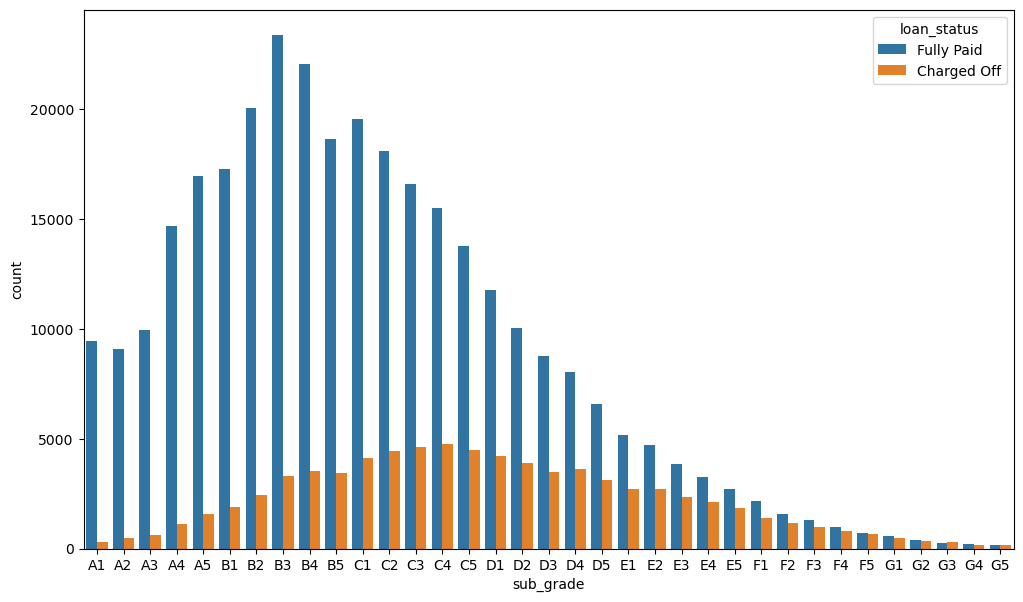

In [64]:
plt.figure(figsize=(12,7))
sns.countplot(x="sub_grade",hue="loan_status",order=sub_order,data=df)
plt.show()

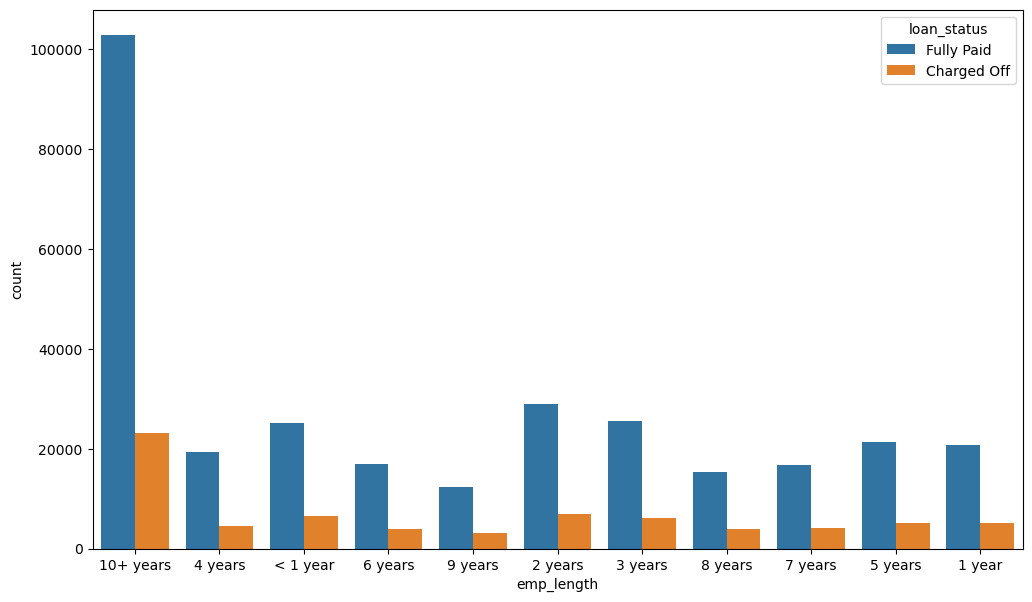

In [65]:
plt.figure(figsize=(12,7))
sns.countplot(x="emp_length",hue="loan_status",data=df)
plt.show()

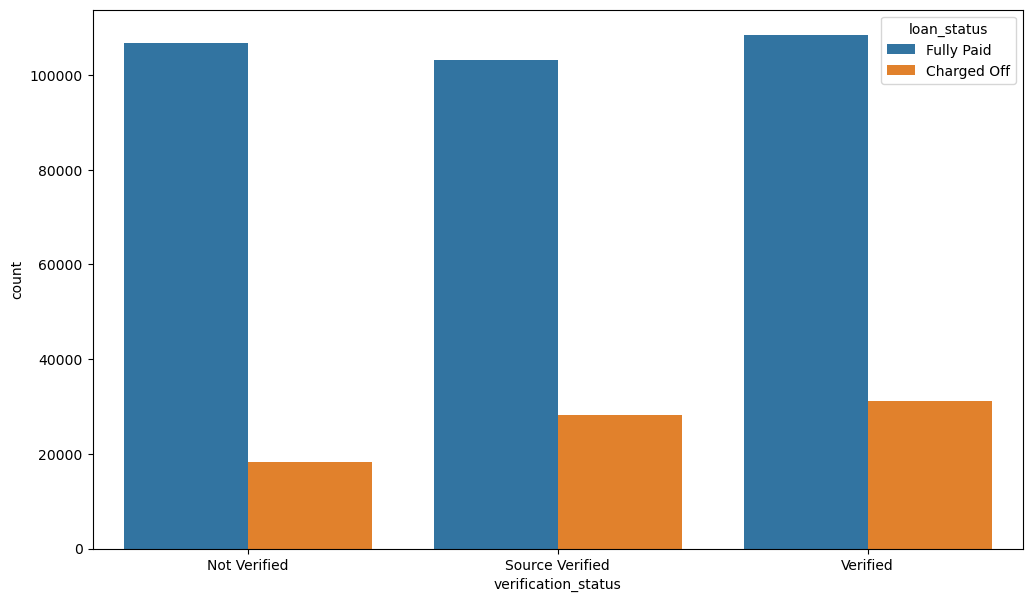

In [66]:
plt.figure(figsize=(12,7))
sns.countplot(x="verification_status",hue="loan_status",data=df)
plt.show()

In [73]:
df["loan_status"].apply(lambda x:1 if x=="Fully Paid" else 0)

0         0
1         0
2         0
3         0
4         0
         ..
396025    0
396026    0
396027    0
396028    0
396029    0
Name: loan_status, Length: 396030, dtype: int64